# Alpha Diversity Sensitivity to Rarefaction

In this follow-up script, we take alpha diversity analysis from script 06 one step further. There, we initially drew one fixed set of 16.000 features to work with. Since our samples contain millions of reads, these 16.000 features make up only a small fraction of the whole sample. We risk losing rare reads and skewing a sample's true diversity. QIIME 2's `Boots` plugin addresses this caveat in microbiome diversity analysis. The principle of bootstrapping stems from macro-ecology, where statistical analysis is conducted on small sub-populations of the whole population. By sub-sampling test populations multiple times, macro-ecology statisticians can estimate the accuracy of a sample statistic for a fixed number of included samples, such as bias, standard error, or confidence intervals. 

The boots plugin provided by QIIME 2 offers two alternative approaches: Bootstrapped diversity analysis and rarefaction-based diversity analysis. The former replaces each result from the previous resampling with the new sub-population of the next draw. The latter stores every result as a separate output file, which can be accessed for downstream analyses. Rarefaction-based analysis is the more commonly used variant for microbiome research.

Rather than drawing new samples for each iteration, we use the same samples throughout the procedure. Instead, we set a fixed feature-level sampling depth. Each time, a new set of reads is drawn from the pool of several million features per sample, resulting in a different alpha diversity vector. This adaptation also enables estimation of statistical accuracy, but - even more importantly - it addresses the principal limitation of rarefaction, namely the loss of underrepresented features in the dataset.

## The Workflow

In notebook 06, 8-mers yielded the clearest group differences in the alpha-diversity analysis. Therefore, the primary analysis in this notebook uses 8-mer features. Notebook 06 used `kmerizer core-metrics`, which integrates rarefaction through its sampling-depth parameter. Since the saved 8-mer table is already rarefied, we create a new, unrarefied 8-mer table from the unrarefied ASV table (`table_fungi_filtered.qza`) and the matching representative sequences (`rep_set_fungi_filtered.qza`), setting the k-mer size to 8.

Next, we run `qiime boots alpha-collection` on that new table to compute Shannon diversity across 100 draws without replacement, sampling 16,000 8-mer occurrences per sample in each draw. 

Finally, we use `qiime boots alpha-average` to obtain the median of the 100 Shannon values for each sample. This will give us one final value per sample. We will need the per-draw values again later for the sensitivity analysis.

Now that we have the Shannon median for every sample, we want to see whether those per-sample values differ from those in the Shannon vector created in script 06. To do this, we conduct a comparative sensitivity analysis between these two .qza files and visualise the results in a paired scatterplot.

However, the median can only give us a glimpse of what happens across these 100 rarefaction draws. For example, for one sample, the Shannon value from one draw can differ greatly from the value from another draw. Therefore, the next step of the sensitivity analysis “zooms in” on the values from each of the 100 draws per sample. We combine the 100 Shannon vectors into a DataFrame with one row per sample and one column per draw.
To analyse how much the values actually differ across draws, we calculate the interquartile range (IQR) for each sample. The IQR is defined as the difference between the 75th and the 25th quartile values. These per-sample IDR values will be visualised in a single boxplot for all 150 samples, allowing us to analyse the overall shape of the plot and identify outlier samples. 

In the final section of the script, we repeat the alpha group comparison and correlation analysis for the mean Shannon vector and compare the results and significant group comparisons to those from the same statistical tests in script 06.

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import qiime2 as q2

from skbio import DistanceMatrix
from qiime2 import Visualization, Artifact, Metadata
from pathlib import Path
from scipy.stats import spearmanr

%matplotlib inline

In [25]:
in_dir  = "../data/processed_ignored"
out_dir = "../data/processed_ignored/06.1_diversity_boots"
vis_dir = "../data/processed/06.1_diversity_boots"

asv_table = f"{in_dir}/03_taxonomy/table_fungi_filtered.qza"
rep_seqs  = f"{in_dir}/03_taxonomy/rep_set_fungi_filtered.qza"
metadata  = f"{in_dir}/06_diversity/Final_metadata_with_GHSL.tsv"
original_kmer8 = f"{in_dir}/06_diversity/kmerizer_k8/shannon_vector.qza"

kmer8_table = f"{out_dir}/kmer8_unrarefied.qza"
alpha_vectors = f"{out_dir}/alpha_vectors_kmer8"
alpha_medians = f"{out_dir}/alpha_medians_kmer8.qza"

!mkdir -p "$out_dir" "$vis_dir"

In [5]:
!qiime boots --help

Usage: qiime boots [OPTIONS] COMMAND [ARGS]...

  Description: A plugin providing bootstrapped and rarefaction-based (i.e.,
  resampled) diversity analyses, designed to mirror the interface of
  q2-diversity.

  Plugin website: https://library.qiime2.org/plugins/caporaso-lab/q2-boots

  Getting user support: Please post to the QIIME 2 forum for help with this
  plugin: https://forum.qiime2.org

Options:
  --version            Show the version and exit.
  --example-data PATH  Write example data and exit.
  --citations          Show citations and exit.
  --help               Show this message and exit.

Commands:
  alpha             Perform resampled alpha diversity, returning average
                    result vector.
  alpha-average     Average alpha diversity vectors.
  alpha-collection  Perform resampled alpha diversity, returning `n` result
                    vectors.
  beta              Perform resampled beta diversity, returning average
                    distance matrix.
  beta

## 1. Create a new 8-mer feature table

In [7]:
!qiime kmerizer seqs-to-kmers --help

Usage: qiime kmerizer seqs-to-kmers [OPTIONS]

  Generate kmers from biological sequences.

Inputs:
  --i-sequences ARTIFACT FeatureData[Sequence | RNASequence |
    ProteinSequence | LinkedSequence]
                          Biological sequences to kmerize.          [required]
  --i-table ARTIFACT FeatureTable[Frequency]
                          Frequencies of sequences per sample.      [required]
Parameters:
  --p-kmer-size INTEGER   Length of kmers to generate.           [default: 16]
  --p-tfidf / --p-no-tfidf
                          If True, kmers will be scored using TF-IDF and
                          output frequencies will be weighted by scores. If
                          False, kmers are counted without TF-IDF scores.
                                                              [default: False]
  --p-max-df VALUE Float % Range(0, 1, inclusive_end=True) | Int
                          Ignore kmers that have a frequency strictly higher
                          than the 

In [12]:
!qiime kmerizer seqs-to-kmers \
    --i-sequences "$rep_seqs" \
    --i-table "$asv_table" \
    --p-kmer-size 8 \
    --o-kmer-table "$kmer8_table"

Saved FeatureTable[Frequency] to: ../data/processed_ignored/06.1_diversity_boots/kmer8_unrarefied.qza


## 2. Repeat rarefaction 100 times

In [13]:
!qiime boots alpha-collection --help

Usage: qiime boots alpha-collection [OPTIONS]

  Given a single feature table as input, this action resamples the feature
  table `n` times to a total frequency of `sampling depth` per sample, and
  then computes the specified alpha diversity metric on each resulting
  `table`. The resulting artifacts can be used, for example, to explore the
  variance across `n` iterations of resampling.

Inputs:
  --i-table ARTIFACT FeatureTable[Frequency | RelativeFrequency |
    PresenceAbsence]      The input feature table.                  [required]
  --i-phylogeny ARTIFACT  The phylogenetic tree to use in phylogenetic
    Phylogeny[Rooted]     diversity calculations. All feature ids in `table`
                          must be present in this tree, but this tree can
                          contain feature ids that are not present in `table`.
                                                                    [optional]
Parameters:
  --p-sampling-depth INTEGER
    Range(1, None)        The tot

In [15]:
!qiime boots alpha-collection \
    --i-table "$kmer8_table" \
    --p-sampling-depth 16000 \
    --p-metric 'shannon' \
    --p-n 100 \
    --p-no-replacement \
    --o-alpha-diversities "$alpha_vectors"
    

Saved Collection[SampleData[AlphaDiversity]] to: ../data/processed_ignored/06.1_diversity_boots/alpha_vectors_kmer8


In [16]:
!qiime boots alpha-average --help

Usage: qiime boots alpha-average [OPTIONS]

  Compute the per-sample average across a collection of alpha diversity
  vectors computed from the same samples.

Inputs:
  --i-data ARTIFACTS... Collection[SampleData[AlphaDiversity]]
                         Alpha diversity vectors to be averaged.    [required]
Parameters:
  --p-average-method TEXT Choices('mean', 'median')
                         Method to use for averaging.               [required]
Outputs:
  --o-average-alpha-diversity ARTIFACT SampleData[AlphaDiversity]
                         The average alpha diversity vector.        [required]
Miscellaneous:
  --output-dir PATH      Output unspecified results to a directory
  --verbose / --quiet    Display verbose output to stdout and/or stderr
                         during execution of this action. Or silence output if
                         execution is successful (silence is golden).
  --example-data PATH    Write example data and exit.
  --citations            Show citatio

## 3. Compute the per-sample mean across the 100 alpha diversity vectors

In [19]:
!qiime boots alpha-average \
    --i-data "$alpha_vectors" \
    --p-average-method "median" \
    --o-average-alpha-diversity "$alpha_medians"

Saved SampleData[AlphaDiversity] to: ../data/processed_ignored/06.1_diversity_boots/alpha_medians_kmer8.qza


## 4. Sensitivity check

**For each sample, we compare the original shannon value (script 06) to the median of the 100 per-sample values (script 06.1).**

In [27]:
original_alpha = Artifact.load(original_kmer8).view(pd.Series)
boots_alpha = Artifact.load(alpha_medians).view(pd.Series)

alpha_comparison = pd.concat(
    [
        original_alpha.rename("original"),
        boots_alpha.rename("repeated_rarefaction_median"),
    ],
    axis=1,
    join="inner",
)

display(alpha_comparison.head())
len(alpha_comparison)

,original,repeated_rarefaction_median
ERR5327198,7.681926,7.645179
ERR5327199,7.353891,7.330839
ERR5327266,7.197232,7.181340
ERR5327282,8.122781,8.089174
ERR5327284,7.605549,7.554880


150

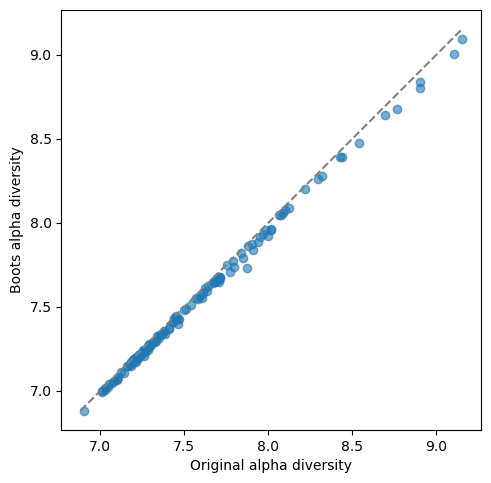

In [36]:
original = alpha_comparison["original"]
boots = alpha_comparison["repeated_rarefaction_median"]

low = min(original.min(), boots.min())
high = max(original.max(), boots.max())

fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(original, boots, alpha=0.6)
ax.plot([low, high], [low, high], "--", color="gray")
ax.set(
    xlabel="Original alpha diversity",
    ylabel="Boots alpha diversity",
    aspect="equal",
)
fig.tight_layout()
plt.show()

**How to read the scatterplot:**

Each blue dot represents one of the 150 samples used for both scripts. The dashed line depicts the 1:1 reference line. Since our dots align almost perfectly with the reference line, we can deduct that the original 8-mer alpha-diversity estimates were close to the per-sample medians from the 100 rarefaction draws.

The scatterplot compared the original value with the computed median for each sample. Now we want to see how much each sample's 8-mer alpha diversity varied across the draws.<br>

For this sensitivity check, we create a DataFrame with 150 rows (samples) and 100 columns (rarefaction draws). Each cell holds the corresponding 8-mer alpha-diversity value.

The first step in building the DataFrame is to list the `.qza` files produced by `alpha-collection` in draw order. Each filename contains the draw number, followed by `.qza`.

By default, `sorted()` compares paths as text, which places `10.qza` immediately after `1.qza`. We use `key=lambda path: int(path.stem)` to take the filename without `.qza` and convert it to an integer for sorting. This gives us the order `0.qza`, `1.qza`, `2.qza`, and so on.

In [43]:
draw_files = sorted(
    Path(alpha_vectors).glob("*.qza"),
    key=lambda path: int(path.stem),
)

print(len(draw_files))  # Expected: 100
print(draw_files[0])   # Path to the first file in the sorted list

100
../data/processed_ignored/06.1_diversity_boots/alpha_vectors_kmer8/0.qza


Below, we use a simplified test command to combine two Series, namely the first and second draws from our 100-draw pipeline, into a small two-column DataFrame. For this, we use `pd.concat()`.

In [44]:
first_draw = Artifact.load(str(draw_files[0])).view(pd.Series)
second_draw = Artifact.load(str(draw_files[1])).view(pd.Series)

two_draws = pd.concat(
    [first_draw.rename("first_draw"), second_draw.rename("second_draw")],
    axis=1,
)

display(two_draws.head())

,first_draw,second_draw
ERR5327198,7.630645,7.643887
ERR5327199,7.338924,7.349506
ERR5327266,7.180031,7.181040
ERR5327282,8.094389,8.089183
ERR5327284,7.557225,7.551359


Since we have 100 artifacts to concatenate in this manner, we use a `for` loop. It loads one `.qza` file at a time, names its Series after the file, and adds it to the list. We then use `pd.concat()` to combine all 100 Series into one DataFrame.

In [45]:
draw_series = []

for path in draw_files:
    draw = Artifact.load(str(path)).view(pd.Series)
    draw = draw.rename(path.stem)
    draw_series.append(draw)

alpha_draws = pd.concat(draw_series, axis=1)

print(alpha_draws.shape) # Expected: 150 rows, 100 columns
display(alpha_draws.iloc[:5, :4])

(150, 100)


,0,1,2,3
ERR5327198,7.630645,7.643887,7.647948,7.634454
ERR5327199,7.338924,7.349506,7.320490,7.335621
ERR5327266,7.180031,7.181040,7.181312,7.176180
ERR5327282,8.094389,8.089183,8.085024,8.090588
ERR5327284,7.557225,7.551359,7.567349,7.570763


We now calculate the interquartile range (IQR) of the 100 rarefaction values for each sample. The IQR is the difference between the 75th and 25th percentiles. We then summarize the 150 sample IQRs in one boxplot to see how much alpha diversity typically varies across draws and whether some samples vary more across draws than others. A taller box means that the middle 50% of the sample IQRs span a wider range.

Typical sample IQR (median): 0.0094


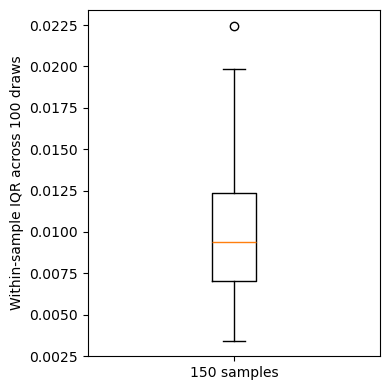

In [51]:
q25 = alpha_draws.quantile(0.25, axis=1)
q75 = alpha_draws.quantile(0.75, axis=1)
sample_iqr = q75 - q25

print(f"Typical sample IQR (median): {sample_iqr.median():.4f}")

fig, ax = plt.subplots(figsize=(4, 4))
ax.boxplot(sample_iqr)
ax.set_xticks([1], ["150 samples"])
ax.set_ylabel("Within-sample IQR across 100 draws")
fig.tight_layout()
plt.show()

To identify the outlier at the top of the boxplot and other samples with a high IQR, we list the five sample IDs with the highest IQRs.

In [52]:
display(sample_iqr.sort_values(ascending=False).head())

ERR5327517    0.022460
ERR5327432    0.019838
ERR5327529    0.019584
ERR5327412    0.019449
ERR5327314    0.019190
dtype: float64

Across the 150 samples, the median within-sample IQR was approximately 0.0094. Sample `ERR5327517` had the highest IQR at 0.02246, meaning that the middle 50% of its 100 rarefaction values spanned 0.02246 alpha-diversity units.

These values show how much the 8-mer alpha-diversity estimate can vary for the same sample when we repeat rarefaction. To see whether this variation affects our original finding, we repeat the same metadata comparison for each of the 100 draws and check how much the result changes.

### 4.2 Group Comparisons and Correlations

We repeat the two commands, `alpha-group-significance` and `alpha-correlation`, from notebook 06. We use the median 8-mer Shannon vector from the 100 rarefaction draws as input. The metadata file is the same as in notebook 06.

In [54]:
!qiime diversity alpha-group-significance \
  --i-alpha-diversity "$alpha_medians" \
  --m-metadata-file "$metadata" \
  --o-visualization "$vis_dir/median_group_significance.qzv"

!qiime diversity alpha-correlation \
  --i-alpha-diversity "$alpha_medians" \
  --m-metadata-file "$metadata" \
  --o-visualization "$vis_dir/median_correlation.qzv"

Saved Visualization to: ../data/processed/06.1_diversity_boots/median_group_significance.qzv
Saved Visualization to: ../data/processed/06.1_diversity_boots/median_correlation.qzv


**Results**

| Diet pair | Baseline q | Median-based q | Δq |
|---|---:|---:|---:|
| Omnivore vs. Omnivore without red meat | **0.035747** | **0.044966** | +0.009219 |
| Omnivore vs. Vegan | **0.017215** | **0.018588** | +0.001373 |
| Omnivore vs. Vegetarian | 0.683600 | 0.744391 | +0.060791 |
| Omnivore vs. Vegetarian who eats seafood | **0.034714** | **0.027242** | −0.007472 |
| Omnivore without red meat vs. Vegan | **0.017215** | **0.018588** | +0.001373 |
| Omnivore without red meat vs. Vegetarian | 0.172867 | 0.134817 | −0.038050 |
| Omnivore without red meat vs. Vegetarian who eats seafood | **0.017215** | **0.018588** | +0.001373 |
| Vegan vs. Vegetarian | **0.017215** | **0.018588** | +0.001373 |
| Vegan vs. Vegetarian who eats seafood | 0.071300 | 0.134183 | +0.062883 |
| Vegetarian vs. Vegetarian who eats seafood | **0.019647** | **0.019647** | 0.000000 |

Δq is the median-based q-value minus the baseline q-value.

The same seven of ten pairwise diet comparisons had q < 0.05 when we used the per-sample median 8-mer Shannon values across 100 repeated rarefaction draws. The largest shift was for Vegan versus Vegetarian who eats seafood, where q increased from 0.071300 to 0.134183. In none of the group comparisons - diet or other metadata columns - did the bootstrapping lead a to gain or loss of significance. 